# Week 10: Computer Vision - OpenCV and Image Preparation

Computer vision is getting computers to extract information from images. The first step is always the same idea we saw with text: a model cannot "see", so we turn an image into numbers and prepare those numbers carefully. Today we use OpenCV (`cv2`), the most widely used computer vision library, to prepare images, clean them up, find edges, count objects, and detect faces.

**Key terms for today**
- Pixel: one dot of an image. A pixel's value is a number from 0 (dark) to 255 (bright).
- Channel: a color image has three channels (red, green, blue), each its own grid of numbers
- Grayscale: one channel only, so each pixel is a single brightness value
- Resolution: the width and height of the image in pixels
- Preprocessing: getting images into a consistent, clean form before a model uses them
- Kernel (filter): a small grid of numbers slid across the image to blur, sharpen, or find edges
- Edge: a place where brightness changes sharply, usually an object boundary
- Threshold: a cutoff that turns a grayscale image into black and white
- Contour: the outline of a white region, used to find and count objects

In Week 7 our digit network took pixels as input. Convolutional neural networks (CNNs) work like the kernels in Step 2, except the network learns the kernel values itself. Early layers find edges, later layers find shapes and objects. Today is the classical toolbox that comes before and alongside those networks.


In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import requests
from skimage import data

def show(images, titles=None, size=4):
    """Display one or more images side by side. Expects RGB or grayscale."""
    if not isinstance(images, list):
        images = [images]
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size))
    axes = np.atleast_1d(axes)
    for i, (ax, img) in enumerate(zip(axes, images)):
        if img.ndim == 2:
            ax.imshow(img, cmap='gray', vmin=0, vmax=255 if img.dtype == np.uint8 else 1, interpolation='nearest')
        else:
            ax.imshow(img, interpolation='nearest')
        ax.axis('off')
        if titles:
            ax.set_title(titles[i], fontsize=10)
    plt.tight_layout()
    plt.show()

def load_url_image(url):
    """Download an image and return it as RGB. OpenCV decodes images in BGR order, so we convert."""
    raw = np.frombuffer(requests.get(url).content, np.uint8)
    return cv2.cvtColor(cv2.imdecode(raw, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)

pd.set_option('display.float_format', '{:,.2f}'.format)
print('OpenCV version:', cv2.__version__)

OpenCV version: 4.14.0


---
## Step 0 - Images Are Arrays of Numbers

A grayscale image is a 2D grid (height by width). A color image is a 3D array: height by width by 3 channels. Every value is a whole number from 0 to 255.

**Demo image:** the astronaut photo that ships with scikit-image (NASA, public domain).

A common gotcha: OpenCV stores color channels in **BGR** order (blue first), while most other tools, including matplotlib, expect **RGB**. If you forget to convert, the colors look wrong.

Shape (height, width, channels): (512, 512, 3)
Data type: uint8  Smallest value: 0  Largest value: 255
Pixel at row 100, column 200 (R, G, B): [81 57 17]


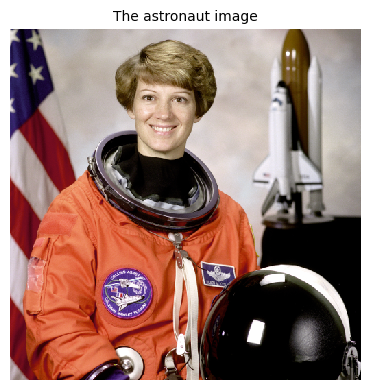

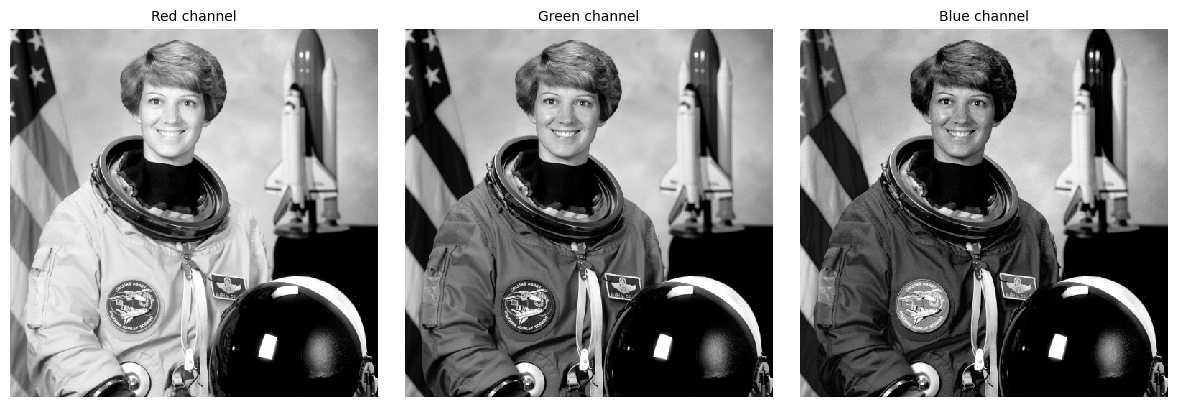

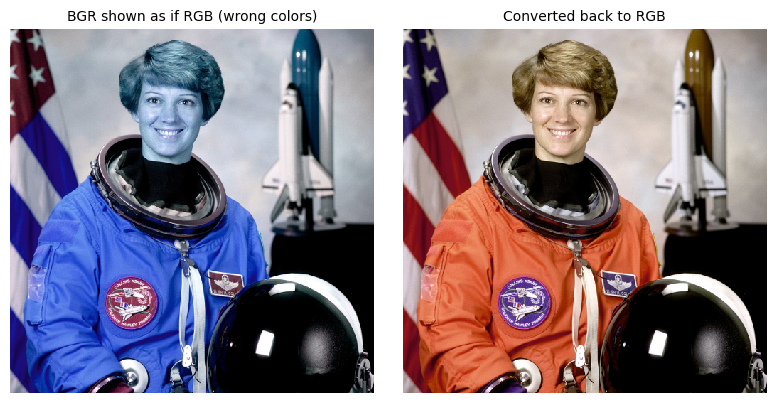

In [2]:
astronaut = data.astronaut()   # RGB array

print('Shape (height, width, channels):', astronaut.shape)
print('Data type:', astronaut.dtype, ' Smallest value:', astronaut.min(), ' Largest value:', astronaut.max())
print('Pixel at row 100, column 200 (R, G, B):', astronaut[100, 200])
show(astronaut, ['The astronaut image'])

# The three channels, each shown as a grayscale grid
red, green, blue = astronaut[:, :, 0], astronaut[:, :, 1], astronaut[:, :, 2]
show([red, green, blue], ['Red channel', 'Green channel', 'Blue channel'])

# The BGR gotcha
bgr = cv2.cvtColor(astronaut, cv2.COLOR_RGB2BGR)
show([bgr, cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)], ['BGR shown as if RGB (wrong colors)', 'Converted back to RGB'])

### Your Turn - Look inside a color image

**Your image:** a photo of a cat with orange fur, also from scikit-image.

TODO: set `CHANNEL` to 0 (red), 1 (green), or 2 (blue). Run it for all three and compare.

In [3]:
cat = data.chelsea()

CHANNEL = None   # TODO: 0 (red), 1 (green) or 2 (blue)
assert CHANNEL in (0, 1, 2), 'Set CHANNEL to 0, 1 or 2 above first, then re-run this cell.'

names = ['Red', 'Green', 'Blue']
print('Shape:', cat.shape)
show([cat, cat[:, :, CHANNEL]], ['Original', f'{names[CHANNEL]} channel only'])
print(f'Average {names[CHANNEL].lower()} value across the image: {cat[:, :, CHANNEL].mean():.0f} out of 255')

AssertionError: Set CHANNEL to 0, 1 or 2 above first, then re-run this cell.

**Your answers:**
1. Compare the red, green, and blue channels. In which channel does the cat's orange fur look brightest, and in which darkest? Why?
2. How many numbers are stored in this color image in total (height times width times channels)?

---
## Step 1 - Image Preparation

Models need every image in the same form. Common preparation steps:

1. **Grayscale:** drop color when it does not matter. This cuts the data to one third.
2. **Resize:** make every image the same width and height. Smaller images are faster to process but lose detail.
3. **Scale values:** divide by 255 so values run from 0 to 1, which neural networks train on more easily.

Every pixel value becomes one input feature for a model. A 28 by 28 grayscale image (like the digits in Week 7) has 784 features. A full-size color photo has hundreds of thousands.

,shape,number of values,smallest,largest
original,"(512, 512, 3)",786432,0.00,255.00
grayscale,"(512, 512)",262144,0.00,255.00
resized 64x64,"(64, 64)",4096,0.00,254.00
scaled to 0-1,"(64, 64)",4096,0.00,1.00


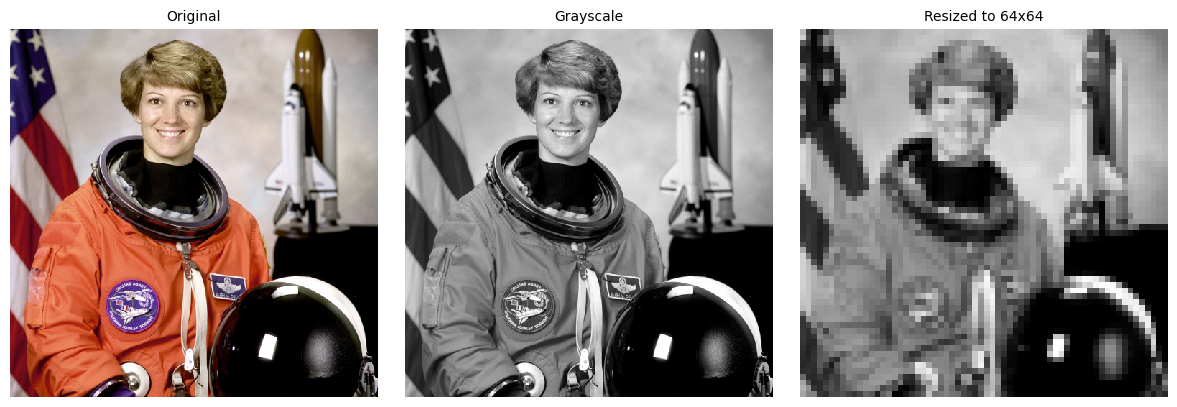

In [4]:
gray = cv2.cvtColor(astronaut, cv2.COLOR_RGB2GRAY)
small = cv2.resize(gray, (64, 64), interpolation=cv2.INTER_AREA)
scaled = small / 255.0

prep = pd.DataFrame({
    'shape': [astronaut.shape, gray.shape, small.shape, scaled.shape],
    'number of values': [astronaut.size, gray.size, small.size, scaled.size],
    'smallest': [astronaut.min(), gray.min(), small.min(), scaled.min()],
    'largest': [astronaut.max(), gray.max(), small.max(), scaled.max()],
}, index=['original', 'grayscale', 'resized 64x64', 'scaled to 0-1'])
display(prep)
show([astronaut, gray, small], ['Original', 'Grayscale', 'Resized to 64x64'])

### Your Turn - Prepare the cat image

TODO: set two values.
- `NEW_SIZE`: the width and height to resize to (try 8, 16, 32, 128)
- `GRAYSCALE`: `True` to convert to grayscale first, or `False` to keep color

In [ ]:
NEW_SIZE = None    # TODO: try 8, 16, 32, 128
GRAYSCALE = None   # TODO: True or False
assert NEW_SIZE is not None and GRAYSCALE is not None, 'Set NEW_SIZE and GRAYSCALE above first, then re-run this cell.'

img = cv2.cvtColor(cat, cv2.COLOR_RGB2GRAY) if GRAYSCALE else cat
resized = cv2.resize(img, (NEW_SIZE, NEW_SIZE), interpolation=cv2.INTER_AREA)

show([cat, resized], ['Original', f'Resized to {NEW_SIZE}x{NEW_SIZE}'], size=5)
print('Original number of values:', cat.size)
print('After preparation:', resized.size, f'({resized.size / cat.size:.2%} of the original)')

**Your answers:**
1. At what size could you no longer recognize the cat? What does that say about the trade-off between small images and detail?
2. The original cat photo is wider than it is tall, but we resized it to a square. What happened to its shape, and why might that matter?

---
## Step 2 - Filters and Noise Removal

A **kernel** is a small grid of numbers. Slide it across the image, and at each position every pixel's new value becomes a weighted sum of itself and its neighbors. Different kernels do different jobs:

- Blur kernel: every weight is equal, so each pixel becomes the average of its neighborhood (smooths out noise)
- Sharpen kernel: boosts the center pixel and subtracts the neighbors (emphasizes detail)
- Edge kernel: weights sum to zero, so flat areas become black and only sudden changes remain

Real photos also contain noise (random specks from the camera sensor or a poor connection). Two common ways to clean it up: **Gaussian blur** (a weighted average) and **median blur** (replace each pixel with the median of its neighbors).

In [ ]:
kernels = {
    'Blur': np.ones((5, 5)) / 25,
    'Sharpen': np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
    'Edge': np.array([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]]),
}
filtered = [cv2.filter2D(gray, -1, k) for k in kernels.values()]
show([gray] + filtered, ['Grayscale'] + list(kernels), size=3.5)

In [ ]:
# Demo: add random (Gaussian) noise, then clean it up
rng = np.random.default_rng(42)
noisy = np.clip(gray + rng.normal(0, 25, gray.shape), 0, 255).astype(np.uint8)

gauss = cv2.GaussianBlur(noisy, (5, 5), 0)
median = cv2.medianBlur(noisy, 5)

def pixel_error(a, b):
    return float(np.mean(np.abs(a.astype(float) - b.astype(float))))

show([noisy, gauss, median], ['Noisy', 'Gaussian blur', 'Median blur'], size=3.5)
print('Average pixel error versus the clean image')
print('  Noisy image:   ', round(pixel_error(noisy, gray), 1))
print('  Gaussian blur: ', round(pixel_error(gauss, gray), 1))
print('  Median blur:   ', round(pixel_error(median, gray), 1))

Both filters reduce the error, but every blur also softens real detail, so bigger is not always better.

### Your Turn - Clean up a damaged photo

We damage the grayscale cat photo with "salt and pepper" noise (random pure white and pure black specks), then you try to repair it.

TODO: set two values.
- `METHOD`: `'gaussian'` or `'median'`
- `KSIZE`: the filter size, which must be an odd number (try 3, 5, 9, 21)

In [ ]:
METHOD = None   # TODO: 'gaussian' or 'median'
KSIZE = None    # TODO: an odd number such as 3, 5, 9, 21
assert METHOD in ('gaussian', 'median'), "Set METHOD to 'gaussian' or 'median' above first, then re-run this cell."
assert KSIZE is not None and KSIZE % 2 == 1, 'Set KSIZE to an odd number above first, then re-run this cell.'

cat_gray = cv2.cvtColor(cat, cv2.COLOR_RGB2GRAY)

rng = np.random.default_rng(1)
damaged = cat_gray.copy()
specks = rng.random(cat_gray.shape)
damaged[specks < 0.05] = 0      # black specks
damaged[specks > 0.95] = 255    # white specks

if METHOD == 'gaussian':
    repaired = cv2.GaussianBlur(damaged, (KSIZE, KSIZE), 0)
else:
    repaired = cv2.medianBlur(damaged, KSIZE)

show([damaged, repaired], ['Damaged', f'{METHOD.capitalize()} blur, size {KSIZE}'], size=5)
print('Average pixel error versus the clean image')
print('  Damaged:  ', round(pixel_error(damaged, cat_gray), 1))
print('  Repaired: ', round(pixel_error(repaired, cat_gray), 1))

**Your answers:**
1. Which method repaired the damage better, Gaussian or median? Try both at the same `KSIZE`. Why do you think one works better on specks?
2. What happens to the photo as you make `KSIZE` very large? Find the size with the lowest error.

---
## Step 3 - Edges, Thresholding, and Counting Objects

**Edges.** The Canny edge detector marks the places where brightness changes sharply. It takes two thresholds. A change stronger than the high threshold is definitely an edge. A change weaker than the low threshold is ignored. Changes in between count only if they connect to a strong edge. We blur first so noise does not create fake edges.

In [ ]:
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
edges = cv2.Canny(blurred, 100, 200)
show([gray, edges], ['Grayscale', 'Canny edges (low = 100, high = 200)'], size=5)

**Thresholding and counting.** A threshold turns a grayscale image into black and white: pixels brighter than the cutoff become white, the rest black. The white regions are then outlined as contours, and counting contours counts objects. A minimum area setting ignores tiny specks that are not real objects.

**Demo:** an image of shapes on a dark background with camera noise added. We know the true answer is 9.

In [ ]:
def count_objects(gray_img, threshold, min_area):
    blur = cv2.GaussianBlur(gray_img, (5, 5), 0)
    _, mask = cv2.threshold(blur, threshold, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    kept = [c for c in contours if cv2.contourArea(c) >= min_area]
    return mask, kept

def outline(gray_img, contours):
    canvas = cv2.cvtColor(gray_img, cv2.COLOR_GRAY2RGB)
    cv2.drawContours(canvas, contours, -1, (0, 255, 0), 2)
    return canvas

# Build the demo image: 9 bright circles on a dark background, plus noise
shapes = np.full((300, 400), 40, dtype=np.uint8)
for center in [(60, 60), (150, 70), (260, 60), (340, 90), (80, 170), (200, 180), (300, 200), (120, 250), (240, 260)]:
    cv2.circle(shapes, center, 22, 200, -1)
rng = np.random.default_rng(7)
shapes = np.clip(shapes + rng.normal(0, 20, shapes.shape), 0, 255).astype(np.uint8)

mask, found = count_objects(shapes, threshold=120, min_area=100)
show([shapes, mask, outline(shapes, found)], ['Image', 'After thresholding', f'Objects found: {len(found)}'], size=4)

### Your Turn - Edges on the cat

TODO: set `LOW` and `HIGH`, the two Canny thresholds (try LOW 50 and HIGH 150, then LOW 100 and HIGH 300). `LOW` must be smaller than `HIGH`.

In [ ]:
LOW = None    # TODO: lower edge threshold, e.g. 30, 50, 100
HIGH = None   # TODO: upper edge threshold, e.g. 100, 150, 300
assert LOW is not None and HIGH is not None and LOW < HIGH, 'Set LOW and HIGH above first (LOW must be smaller than HIGH), then re-run this cell.'

cat_gray = cv2.cvtColor(cat, cv2.COLOR_RGB2GRAY)
cat_blur = cv2.GaussianBlur(cat_gray, (5, 5), 0)
cat_edges = cv2.Canny(cat_blur, LOW, HIGH)

show([cat_gray, cat_edges], ['Grayscale', f'Canny edges (low = {LOW}, high = {HIGH})'], size=5)
print('Share of pixels marked as edges:', f'{(cat_edges > 0).mean():.1%}')

### Your Turn - Count the coins

**Your image:** a photo of coins on a table. The true number of coins is **24**.

TODO: set two values.
- `THRESHOLD`: brightness cutoff from 0 to 255 (try 60, 100, 140, 160)
- `MIN_AREA`: smallest outline, in pixels, that counts as a coin (try 20, 100, 500)

In [ ]:
coins = data.coins()   # grayscale photo of coins

THRESHOLD = None   # TODO: 0 to 255. Try 60, 100, 140, 160.
MIN_AREA = None    # TODO: try 20, 100, 500
assert THRESHOLD is not None and MIN_AREA is not None, 'Set THRESHOLD and MIN_AREA above first, then re-run this cell.'

coin_mask, coin_contours = count_objects(coins, THRESHOLD, MIN_AREA)
show([coins, coin_mask, outline(coins, coin_contours)], ['Coins', 'After thresholding', f'Objects found: {len(coin_contours)} (true count: 24)'], size=4.5)

**Your answers:**
1. What `LOW` and `HIGH` gave the cleanest edges on the cat? What happened with thresholds that were too low, and too high?
2. What is the closest you can get to the true count of 24? What combination of settings did you use?
3. Why is it hard to get exactly 24 with one threshold for the whole image? Look at the mask: what goes wrong?

---
## Step 4 - Detecting Faces with a Pretrained Detector

OpenCV ships with pretrained **Haar cascade** detectors. The face detector (from 2001) slides a window across the image at many sizes, checking simple light and dark patterns that faces tend to have (eyes darker than cheeks, for example). Nobody trains anything here. The detector is fast, but it mainly finds front-facing faces and can be fooled. Modern detectors use CNNs and are more accurate.

Two settings control how it behaves:
- `scaleFactor`: how much the search window grows between passes. Closer to 1 is more thorough and slower.
- `minNeighbors`: how many overlapping detections are needed before it accepts a face. Higher is stricter, so fewer false alarms but more missed faces.

Face **detection** only finds where faces are. It does not say whose face it is (that is face recognition, a different and more sensitive task with privacy and bias concerns).

In [ ]:
face_detector = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

def detect_faces(rgb_image, scale_factor, min_neighbors):
    gray_img = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2GRAY)
    return face_detector.detectMultiScale(gray_img, scaleFactor=scale_factor, minNeighbors=min_neighbors)

def draw_boxes(rgb_image, faces):
    canvas = rgb_image.copy()
    for (x, y, w, h) in faces:
        cv2.rectangle(canvas, (x, y), (x + w, y + h), (0, 255, 0), 3)
    return canvas

strict = detect_faces(astronaut, 1.1, 5)
loose = detect_faces(astronaut, 1.1, 1)

show([draw_boxes(astronaut, strict), draw_boxes(astronaut, loose)],
     [f'minNeighbors = 5: {len(strict)} face(s)', f'minNeighbors = 1: {len(loose)} face(s)'], size=5)

With `minNeighbors = 1` the detector accepts weak matches and reports extra "faces" that are not faces (false positives). The strict setting finds the one real face.

### Your Turn - Find faces in a soccer photo

**Your image:** a soccer photo (from the OpenCV sample images) with a face and a busy background.

TODO: set two values.
- `SCALE_FACTOR`: a number greater than 1 (try 1.05, 1.1, 1.3)
- `MIN_NEIGHBORS`: a whole number (try 1, 3, 5, 8)

In [ ]:
base = 'https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/'
soccer = load_url_image(base + 'messi5.jpg')

SCALE_FACTOR = None    # TODO: greater than 1. Try 1.05, 1.1, 1.3.
MIN_NEIGHBORS = None   # TODO: a whole number. Try 1, 3, 5, 8.
assert SCALE_FACTOR is not None and MIN_NEIGHBORS is not None and SCALE_FACTOR > 1, 'Set SCALE_FACTOR (greater than 1) and MIN_NEIGHBORS above first, then re-run this cell.'

faces = detect_faces(soccer, SCALE_FACTOR, MIN_NEIGHBORS)
show([draw_boxes(soccer, faces)], [f'scaleFactor = {SCALE_FACTOR}, minNeighbors = {MIN_NEIGHBORS}: {len(faces)} face(s) found'], size=8)

**Your answers:**
1. How many faces does the photo actually contain? Which settings found them without false alarms?
2. What happens at `MIN_NEIGHBORS = 1`? What happens when `SCALE_FACTOR` is large, such as 1.3?
3. Run the detector on the cat image (change `soccer` to `cat` in the code). What does it find, and what does that tell you about pretrained detectors?

---
## Step 5 - In-Class Activity (IC-9): What Can Go Wrong in Vision?

Three short tasks. Use the Your Turn cells above and change one setting at a time. Write one or two sentences for each.

**Task 1 (about 3 minutes).** In Step 1, set `GRAYSCALE = True` and compare `NEW_SIZE` of 8 and 64. Record how many values the image has at each size. At what size can you still recognize the cat, and what is lost when images are small?

**Task 2 (about 3 minutes).** In the coin counter, find the setting that gets closest to 24 and record it. Then explain in one sentence why one threshold for the whole image struggles. (Hint: look at the mask.)

**Task 3 (about 2 minutes).** In Step 4, compare `MIN_NEIGHBORS` of 1 and 5 on the soccer photo. Suppose a store uses face detection to count customers entering. Which kind of error would you prefer, extra false faces or missed faces, and which setting would you pick?

**Your answers:**

Task 1:

Task 2:

Task 3:

**To submit for the in-class activity:** upload a screenshot of your best coin count along with your three written answers to the IC-9 module.

---
# Assignment 10 - Prepare, Process, and Explain

Run the notebook from the top first. Write your own explanations; answers that only restate numbers will not get full credit.

## Task 1 - Prepare an image for a model

Write the preparation steps that would turn any color photo into model input, matching the digits from Week 7 (28 by 28, grayscale, values from 0 to 1, as one long row of numbers).

TODO: set `SIZE`, the width and height to resize to. Use 28 to match the Week 7 digits.

In [ ]:
SIZE = None   # TODO: use 28 to match the Week 7 digit images
assert SIZE is not None, 'Set SIZE above first, then re-run this cell.'

def prepare_for_model(rgb_image, size):
    gray_img = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2GRAY)
    small_img = cv2.resize(gray_img, (size, size), interpolation=cv2.INTER_AREA)
    return (small_img / 255.0).flatten()

features = prepare_for_model(cat, SIZE)
print('Number of features:', features.shape[0])
print('Smallest value:', features.min().round(2), ' Largest value:', features.max().round(2))

**Task 1 answer.** How many features does the prepared cat image have, and how does that compare with the original photo? Why must a model's training images and its prediction images go through exactly the same preparation steps?

**Your answer:**

## Task 2 - Edges on an image of your choice

Pick another built-in image and run the preparation, blur, and edge steps on it.

TODO: set three values.
- `IMAGE_NAME`: one of `'coffee'`, `'rocket'`, `'camera'`, `'moon'`, `'page'`
- `LOW` and `HIGH`: your Canny thresholds, with `LOW` smaller than `HIGH`

In [ ]:
IMAGE_NAME = None   # TODO: 'coffee', 'rocket', 'camera', 'moon' or 'page'
LOW2 = None         # TODO: lower edge threshold
HIGH2 = None        # TODO: upper edge threshold
assert IMAGE_NAME in ('coffee', 'rocket', 'camera', 'moon', 'page'), 'Set IMAGE_NAME to one of the listed names first.'
assert LOW2 is not None and HIGH2 is not None and LOW2 < HIGH2, 'Set LOW2 and HIGH2 first (LOW2 must be smaller than HIGH2).'

chosen = getattr(data, IMAGE_NAME)()
chosen_gray = chosen if chosen.ndim == 2 else cv2.cvtColor(chosen, cv2.COLOR_RGB2GRAY)
chosen_edges = cv2.Canny(cv2.GaussianBlur(chosen_gray, (5, 5), 0), LOW2, HIGH2)

show([chosen, chosen_edges], [IMAGE_NAME, f'Canny edges ({LOW2}, {HIGH2})'], size=5)

**Task 2 answer.** What did edge detection capture well in your image, and what did it miss or get wrong? How did changing the thresholds change the result?

**Your answer:**

## Task 3 - Reflection

In 6 to 8 sentences:
1. In this notebook a simple threshold counted coins imperfectly, and a face detector made false detections. When is a classical OpenCV method like these good enough, and when would you need a trained neural network instead?
2. A company wants to detect defective products on a conveyor belt using camera images. List three image preparation steps you would apply, and explain why each matters.
3. Face detection is widely used. Give one benefit and one concern (privacy, bias, or consent), and say how you would decide whether to use it. Would you build your own or call a cloud vision API (Week 7)?

**Your answer:**